# Planets explainer

A two-part explainer as `Scene` classes. "Eight planets" draws the orbits to scale while each planet
circles the Sun through the project's `orbit` behaviour. "700× wider" sets the Sun beside Betelgeuse and
counts a row of 100 Suns on a rolling counter. Saving a scene as SVG or PowerPoint bakes the behaviours
and the per-frame updates into SMIL.

In [1]:
import functools
import shutil

from IPython import display as ipy
import svgwriter as svg

from animations import orbit
from components import Counter, heading, read_planets

The project's theme applies to every drawing below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)

In [3]:
MARGIN = 80
SUN = (90, 470)            # where the Sun sits in "Eight planets"
AU = 36                    # pixels per astronomical unit
WIDER = 700                # Betelgeuse's diameter in Suns
ROW = 100                  # Suns counted in the row
LABELLED = 2               # orbits beyond this many AU get a name; the inner four share one

## Eight planets
The orbits are circles about the Sun with radii in AU, so Neptune's is 78 times Mercury's. Planet sizes
are not to scale (they would be specks). `self.attach` runs the `orbit` behaviour on every planet.

In [4]:
class Planets(svg.Scene):
    """The orbits to scale, the planets moving on them."""

    size = "video-720p"
    fps = 30
    duration = 6.0

    def __init__(self, speed: float = 1.0) -> None:
        self.speed = speed
        super().__init__()

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height).as_role("background")
        title = heading("Eight planets", f"Orbit distances to scale: 1 AU = {AU} px", x=MARGIN, y=MARGIN)
        doc += title
        title.animate.fade_in(0.8)
        sun_x, sun_y = SUN
        orbits = doc.group()
        bodies = doc.group()
        for index, planet in enumerate(read_planets()):
            radius = planet.au * AU
            orbits += svg.circle(sun_x, sun_y, radius).as_role("orbit")
            body = svg.circle(sun_x + radius, sun_y, planet.radius, fill=planet.color)
            bodies += body
            self.attach(body, orbit, cx=sun_x, cy=sun_y, au=planet.au, speed=self.speed)
            if planet.au > LABELLED:
                doc.text(planet.name, x=sun_x + radius, y=sun_y + 44 + index % 2 * 26,
                         text_anchor="middle").as_role("caption")
        orbits.animate.stagger("fade_in", step=0.15, dur=0.6, begin=0.4)
        doc.circle(sun_x, sun_y, 9).as_role("shape").filter = svg.filters.glow(6, color="#ffd166")
        doc.text("Mercury to Mars", x=sun_x, y=sun_y - 70, text_anchor="middle").as_role("caption")

## 700× wider
Betelgeuse is about 700 times wider than the Sun. At this scale the Sun is a 2-pixel dot; `update`
lines up 100 of them while the counter rolls to 100. Seven such rows would span the star.

In [5]:
class Betelgeuse(svg.Scene):
    """The Sun beside Betelgeuse, and a row of Suns counted up."""

    size = "video-720p"
    fps = 30
    duration = 6.0

    def __init__(self, speed: float = 1.0) -> None:
        self.speed = speed
        super().__init__()

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height).as_role("background")
        title = heading("700× wider", "Betelgeuse beside the Sun, to scale", x=MARGIN, y=MARGIN)
        doc += title
        title.animate.fade_in(0.8)
        sun = 1.0
        radius = sun * WIDER
        star = doc.circle(self.width / 2, self.height + radius - 260, radius, fill=svg.gradients.blend(
            "#ffb36b", "#ef6f3c", "#7a1f12", angle=90))
        star.filter = svg.filters.glow(24, color="#ef6f3c", opacity=0.6)
        star.animate.breathe(amount=0.01, period=3)
        star.animate.fade_in(1.2, begin=0.3)
        self.row_y = self.height - 300
        self.row_x = self.width / 2 - ROW * sun
        self.suns = doc.group()
        self.suns.as_role("shape")
        self.counter = Counter(doc, x=self.width - MARGIN - 3 * 40, y=MARGIN + 60, places=3, size=64)
        doc.text(f"a row of {ROW} Suns", x=self.width / 2, y=self.row_y - 24,
                 text_anchor="middle").as_role("caption")
        doc.text("Suns in a row", x=self.width - MARGIN, y=MARGIN + 110, text_anchor="end").as_role("caption")

    def update(self, seconds: float) -> None:
        counted = min(max((seconds * self.speed - 1.5) / 3.0, 0.0), 1.0) * ROW
        while len(self.suns.children) < int(counted):
            index = len(self.suns.children)
            self.suns += svg.circle(self.row_x + 2 * index + 1, self.row_y, 1)
        self.counter.show(counted)

`scenes` is the project's entry: one clip each. Two controls, a time scale and which clip, drive the same
scenes through a function that bakes the chosen one, which `svg.interact` shows in a notebook.

In [6]:
scenes = [Planets, Betelgeuse]
CLIPS = {"Eight planets": Planets, "700× wider": Betelgeuse}


@svg.widgets.controls(
    scene=svg.widgets.Segmented(list(CLIPS), value="Eight planets"),
    speed=svg.widgets.Slider(0.25, 4, step=0.25, value=1.0, label="time scale"),
)
def explainer(doc: svg.Document, *, scene: str = "Eight planets", speed: float = 1.0) -> svg.Document:
    """The chosen clip with its clock running *speed* times as fast, baked into an animated document."""
    return CLIPS[scene](speed).bake()

Every control of `explainer` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [7]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(explainer))

The same function for other control values.

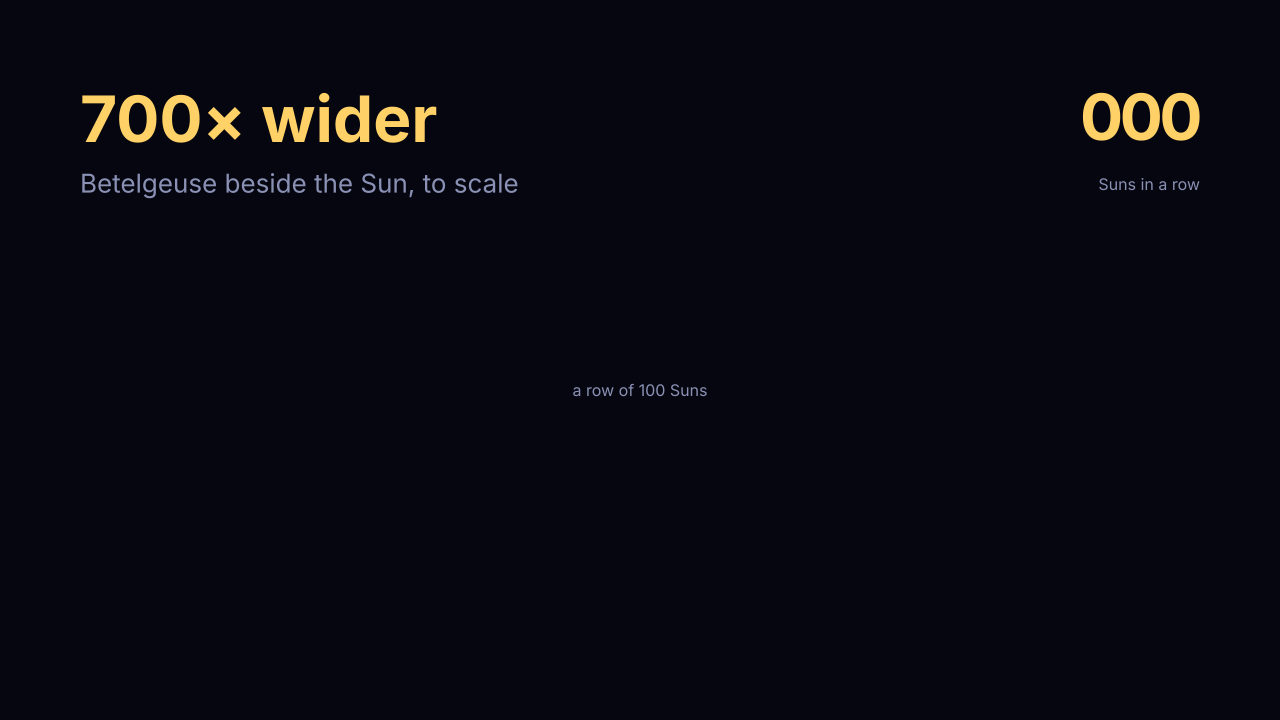

In [8]:
show(explainer, **{'scene': '700× wider'})

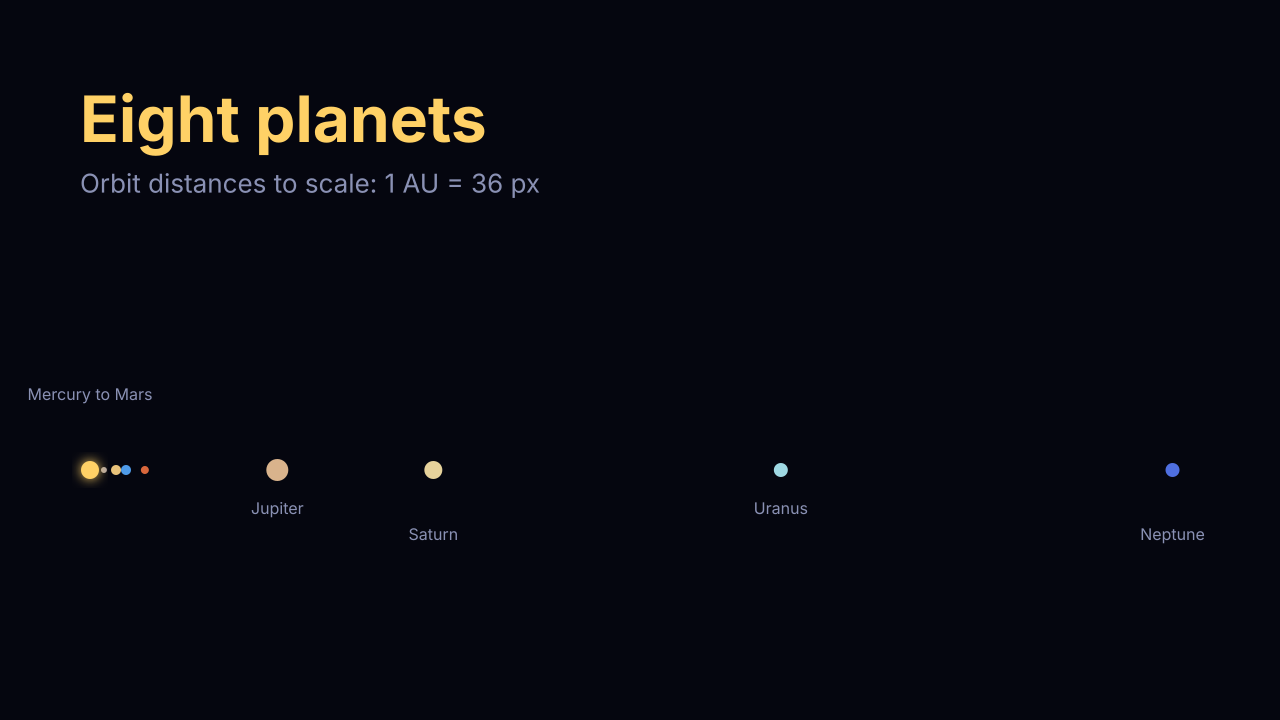

In [9]:
show(explainer, **{'speed': 3.0})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

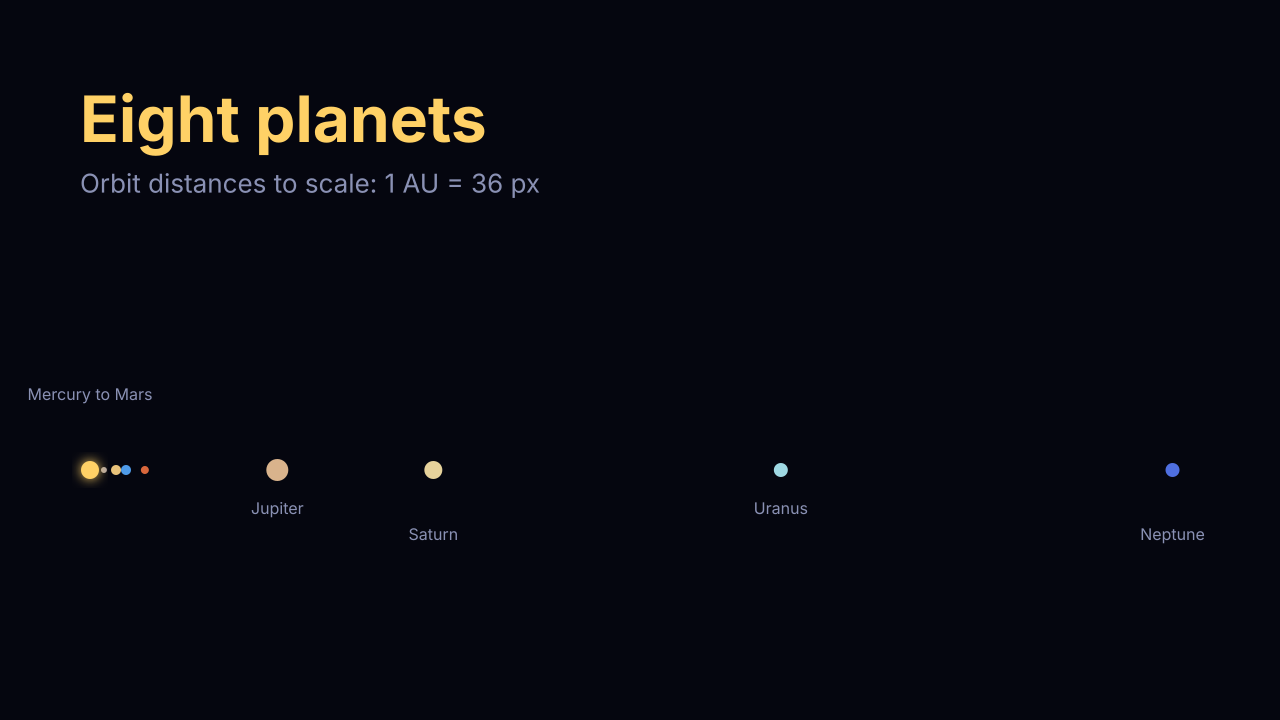

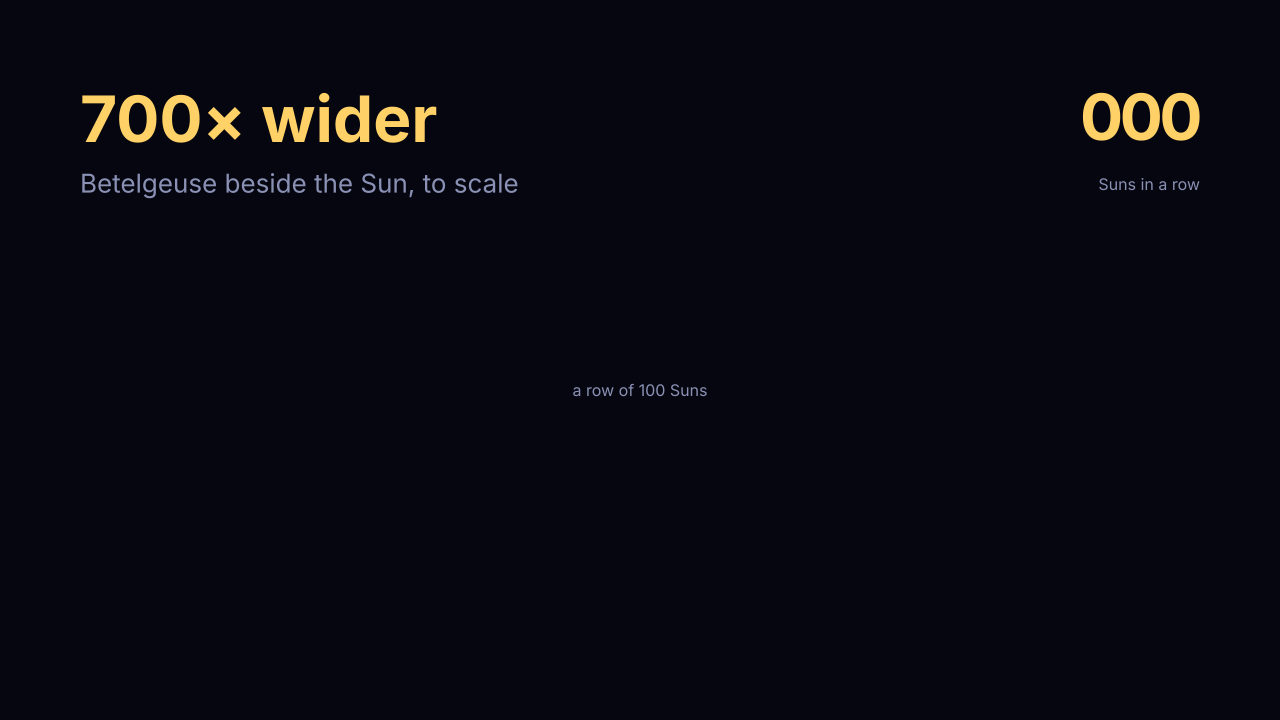

In [10]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))